# Example of the aitlas toolbox in the context of image classification

## Import the required packages

In [ ]:
from aitlas.datasets import IcebergClassificationChallengeDataset
from aitlas.utils import image_loader
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor

## Show images from the dataset

In [ ]:
dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/iceberg_challenge/train.json/data/processed/train.json",
}
dataset = IcebergClassificationChallengeDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 1603


2025-09-30 14:01:32,548 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-09-30 14:01:32,576 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-09-30 14:01:32,605 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


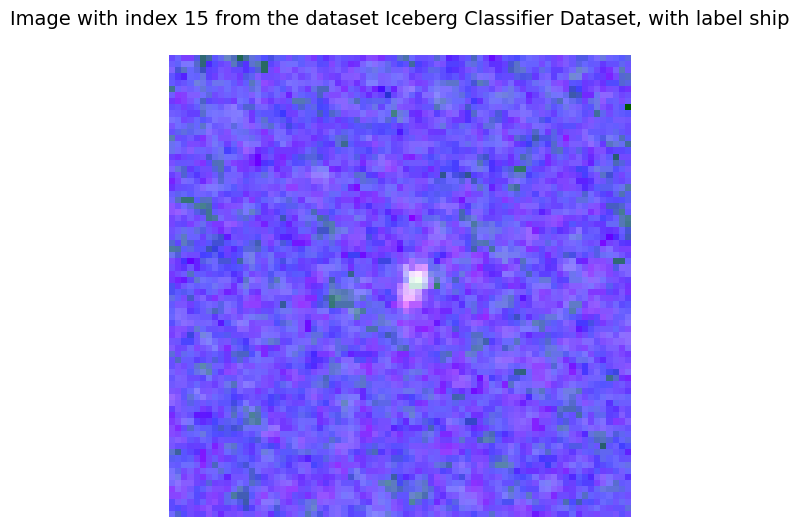

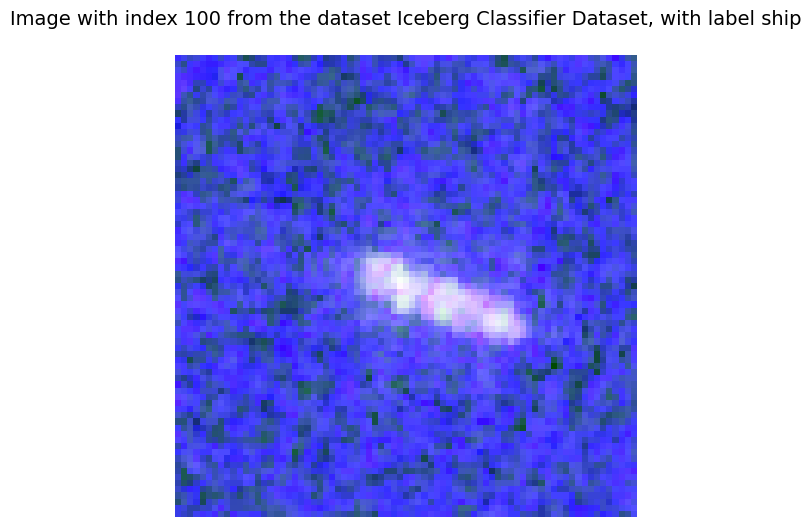

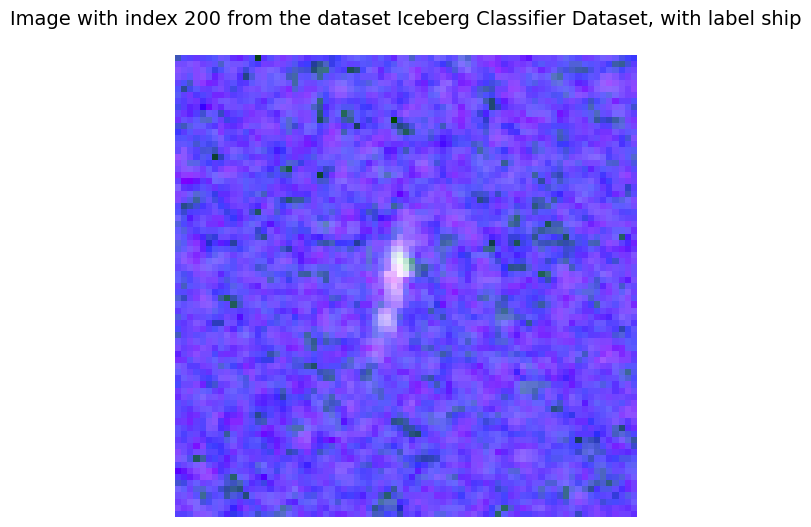

In [89]:
dataset.show_image(15);
dataset.show_image(100);
dataset.show_image(200);

2025-09-30 13:54:46,208 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-09-30 13:54:46,211 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-09-30 13:54:46,214 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-09-30 13:54:46,217 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-09-30 13:54:46,220 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


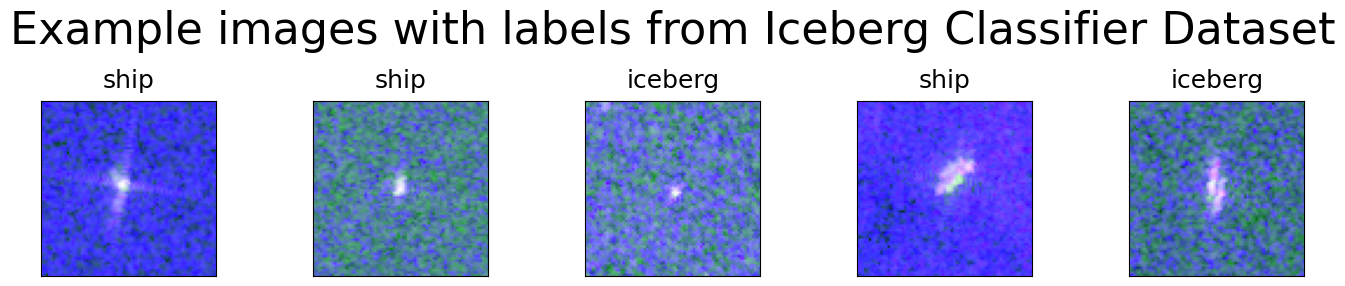

In [81]:
dataset.show_batch(5);

In [82]:
dataset.data_distribution_table()

,Label,Count
0,iceberg,753
1,ship,851


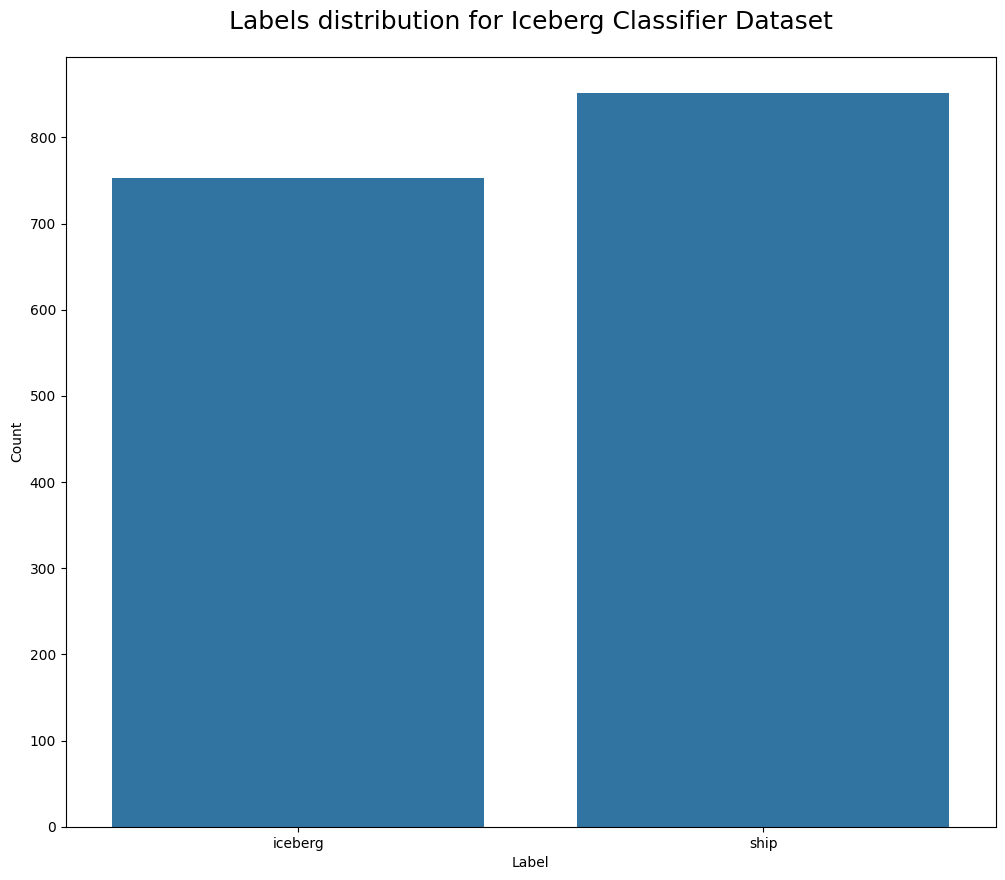

In [23]:
dataset.data_distribution_barchart();

## Load training data ##

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/iceberg_challenge/train.json/data/processed/train.json",
}

train_dataset = IcebergClassificationChallengeDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

len(train_dataset)

1603

## Create the model ##

In [ ]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/iceberg_challenge/"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}

model = VisionTransformer(model_config)
model.prepare()

2025-09-30 13:55:14,788 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-09-30 13:55:14,984 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Start the training ##

In [85]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-09-30 13:55:19,742 INFO Starting training.


training: 100%|██████████| 201/201 [00:17<00:00, 11.64it/s]
2025-09-30 13:55:37,149 INFO epoch: 1, time: 18, loss:  0.44341
testing on train set: 100%|██████████| 201/201 [00:07<00:00, 27.61it/s]
2025-09-30 13:55:47,736 INFO Accuracy:0.8777292576419214, Precision Micro:0.8777292576419214, Precision Macro:0.877279900007812, Precision Weighted:0.8777292576419214, Precision per Class:[0.88470588 0.86985392], Recall Micro:0.8777292576419214, Recall Macro:0.877279900007812, Recall Weighted:0.8777292576419214, Recall per Class:[0.88470588 0.86985392], F1_score Micro:0.8777292576419209, F1_score Macro:0.8772799000078113, F1_score Weighted:0.8777292576419209, F1_score per Class:[0.88470588 0.86985392]
training: 100%|██████████| 201/201 [00:16<00:00, 12.00it/s]
2025-09-30 13:56:04,502 INFO epoch: 2, time: 17, loss:  0.37645
testing on train set: 100%|██████████| 201/201 [00:07<00:00, 27.62it/s]
2025-09-30 13:56:11,799 INFO Accuracy:0.8477854023705552, Precision Micro:0.8477854023705552, Precisi

0.2759721137255579

## Predictions ##

2025-09-30 14:03:27,305 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/iceberg_classifier/checkpoint.pth.tar


8423


2025-09-30 14:03:27,706 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/iceberg_classifier/checkpoint.pth.tar at epoch 11
2025-09-30 14:03:27,734 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-09-30 14:03:27,822 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-09-30 14:03:27,887 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


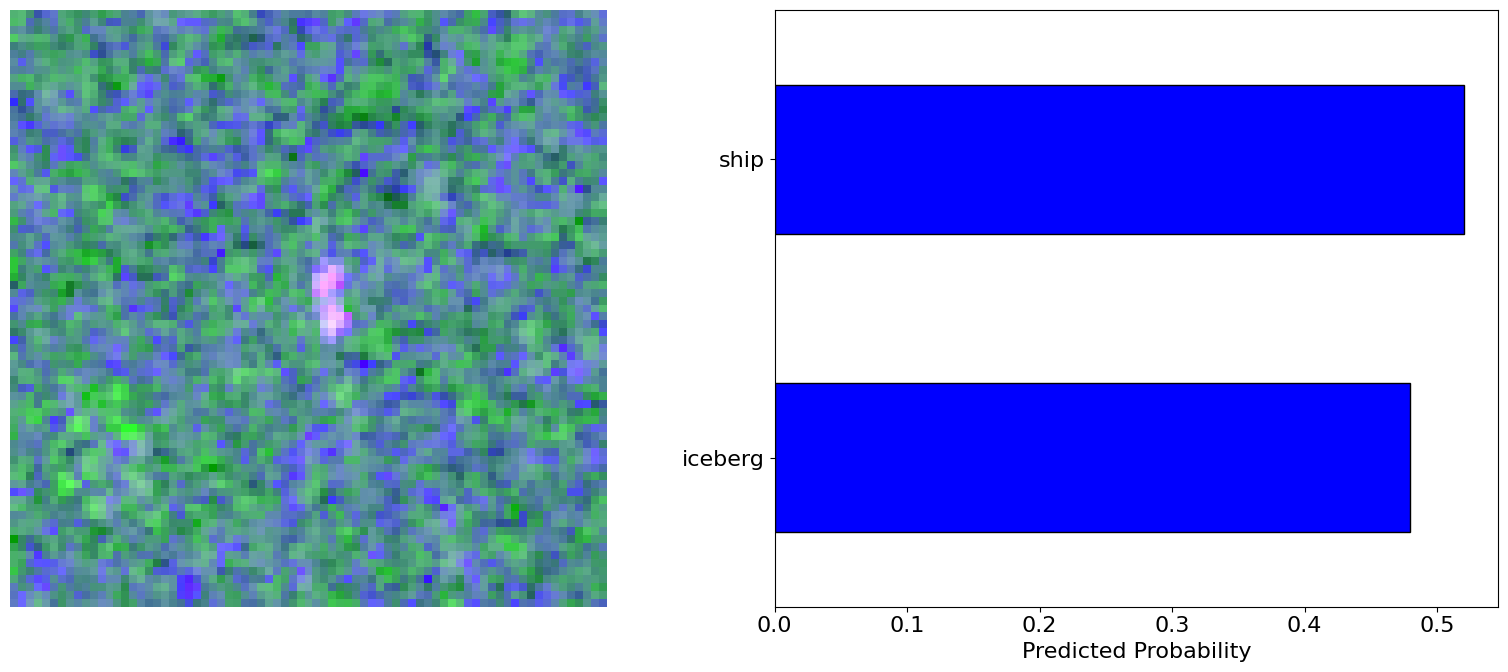

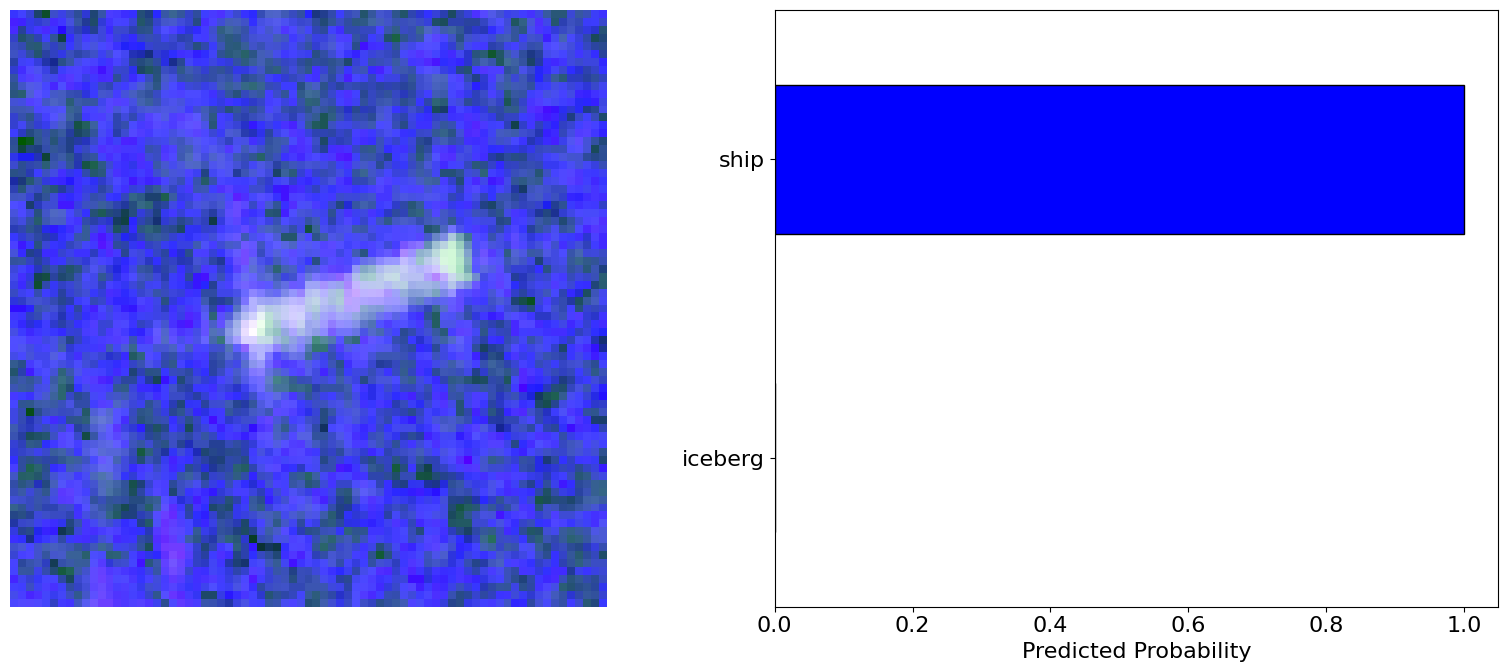

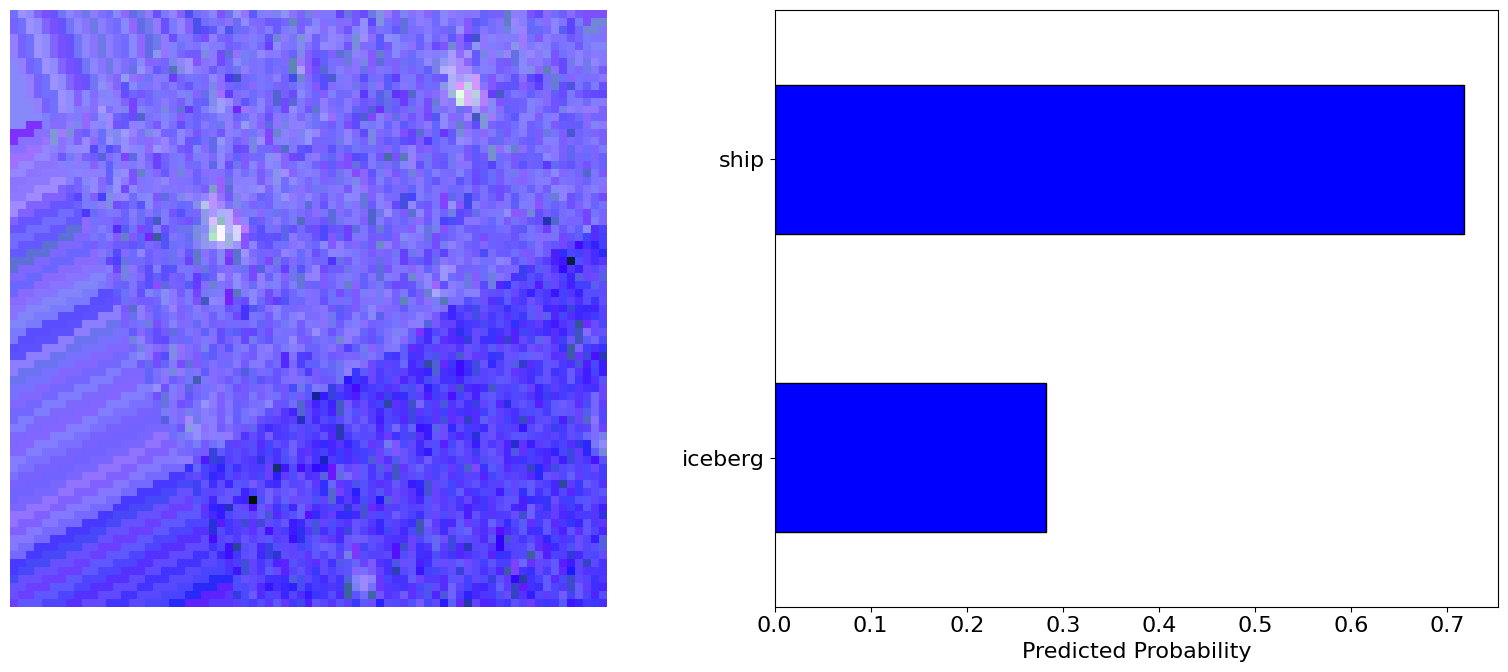

In [ ]:
labels = ["ship","iceberg"]
test_dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/iceberg_challenge/test.json/data/processed/test.json",
}

test_dataset = IcebergClassificationChallengeDataset(test_dataset_config)
print(len(test_dataset))

transform = ResizeCenterCropToTensor()
model_path = "/home/dragik/data/FAIR_EO/experiments/iceberg_challenge/checkpoint.pth.tar"
model.load_model(model_path)

image = test_dataset[0][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[10][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[100][0]
fig = model.predict_image(image, labels, transform)